# 01 · The bus in GPT-2 small (TransformerLens)

AI4Read post 03, *What Is a Hidden State? The Residual Stream, Read and Written*.

This notebook checks, on GPT-2 small, the bookkeeping the post teaches: the residual stream after block L is the
embedding (token + position) plus every attention and MLP write before it. Everything is float32 on the CPU (card flag T7).

Steps (card §10): 1 load · 2 cache one forward pass · 3 per-block additivity · 4 telescoping from the embedding ·
5 stream norm by layer and position · 6 logit lens with and without the final LayerNorm · 7 the W9 toy numbers in numpy ·
8 TransformerLens versus Hugging Face · 9 blank exercises.

**Rule of this notebook.** No statement about library behaviour is made from memory. Each one is either printed from the
installed source by `cite(...)` (file and line of *your* installed version), or shown numerically.

**Out of scope:** induction heads, attention-head algebra, patching, SAEs, eigen-decomposition.

## 0 · Settings

* `LOCAL_ONLY = True` makes every download call fail instead of reaching the network. Run once with `False` to fill the
  Hugging Face cache, then switch to `True` (or set the environment variable `AI4READ_LOCAL_ONLY=1`).
* `TL_API`: `"auto"` uses `TransformerBridge` when the installed TransformerLens has it (version 3 and later; in version 4
  `HookedTransformer` was removed), otherwise the classic `HookedTransformer`. You can force either.

In [1]:
import os
LOCAL_ONLY = False          # set True once gpt2 is in your Hugging Face cache
TL_API = "auto"             # "auto" | "bridge" | "hooked"
TL_MODEL = "gpt2"           # GPT-2 small
PROMPT = "The cat sat on the mat because"

LOCAL_ONLY = os.environ.get("AI4READ_LOCAL_ONLY", str(LOCAL_ONLY)).lower() in ("1", "true", "yes")
TL_API = os.environ.get("AI4READ_TL_API", TL_API)
if LOCAL_ONLY:                       # must be set before transformers / huggingface_hub are imported
    os.environ["HF_HUB_OFFLINE"] = "1"
    os.environ["TRANSFORMERS_OFFLINE"] = "1"
print("LOCAL_ONLY =", LOCAL_ONLY, "| TL_API =", TL_API)

LOCAL_ONLY = True | TL_API = auto


In [2]:
import os, re, math, pathlib, platform, importlib, importlib.metadata as md

def pkg_version(name):
    try:
        return md.version(name)
    except md.PackageNotFoundError:
        return "not installed"

def cite(module, pattern, context=0, max_hits=1, start_after=None):
    """Print file:line for lines matching `pattern` in the INSTALLED source of `module`.
    Line numbers are those of the version installed on this machine."""
    if isinstance(module, str):
        try:
            module = importlib.import_module(module)
        except Exception as e:  # a different library version may have moved the file
            print(f"[module {module} not importable here ({type(e).__name__}); the installed version may differ]")
            return
    path = pathlib.Path(module.__file__)
    parts = path.parts
    cut = max([i for i, p in enumerate(parts) if p in ("site-packages", "dist-packages")] or [0])
    rel = "/".join(parts[cut + 1:])
    lines = path.read_text().splitlines()
    begin = 0
    if start_after is not None:
        begin = next((i for i, l in enumerate(lines) if re.search(start_after, l)), 0)
    hits = [i for i in range(begin, len(lines)) if re.search(pattern, lines[i])][:max_hits]
    if not hits:
        print(f"[pattern not found in {rel}: {pattern!r}; the installed version may differ]")
    for i in hits:
        for j in range(max(0, i - context), min(len(lines), i + context + 1)):
            print(f"{rel}:{j + 1}: {lines[j].rstrip()}")

def err(a, b):
    """(max absolute error, max relative error). Relative = max over positions of
    ||a - b||_2 / ||b||_2, i.e. relative to the stream's norm at that position."""
    d = (a - b).double()
    max_abs = d.abs().max().item()
    rel = (d.norm(dim=-1) / b.double().norm(dim=-1).clamp_min(1e-30)).max().item()
    return max_abs, rel

import numpy as np, pandas as pd, torch, transformers, transformer_lens
import matplotlib
import matplotlib.pyplot as plt
torch.set_grad_enabled(False)
transformers.utils.logging.disable_progress_bar()   # keep saved outputs small
DEVICE, DTYPE = "cpu", torch.float32
pd.set_option("display.width", 160)

print("python      ", platform.python_version(), "|", platform.platform())
for p in ["torch", "transformers", "transformer_lens", "numpy", "pandas", "matplotlib", "huggingface_hub"]:
    print(f"{p:12s}", pkg_version(p))
print("device", DEVICE, "| dtype", DTYPE)

python       3.13.16 | Linux-6.18.44-fc-v153-x86_64-with-glibc2.39
torch        2.14.1
transformers 5.19.0
transformer_lens 4.3.0
numpy        2.5.3
pandas       3.0.5
matplotlib   3.11.2
huggingface_hub 2.2.0
device cpu | dtype torch.float32


## 1 · Load GPT-2 small, twice

TransformerLens can give two versions of the same GPT-2:

* **processed** (`model`): the weights are rewritten on loading (fold the LayerNorm weights into the next linear maps,
  centre the weights that write to the stream, centre the unembedding, fold the value biases). This is what
  `HookedTransformer.from_pretrained` always did and what ARENA uses.
* **raw** (`raw`): the Hugging Face weights unchanged.

The next cell prints, from the installed source, what the loader does by default. In TransformerLens 4.x
`TransformerBridge.boot_transformers` returns *raw* weights and `enable_compatibility_mode()` applies the processing;
in TransformerLens 2.x `from_pretrained` processes and `from_pretrained_no_processing` does not.

In [3]:
def resolve_api(api):
    if api != "auto":
        return api
    try:
        from transformer_lens.model_bridge import TransformerBridge  # noqa: F401
        return "bridge"
    except ImportError:
        return "hooked"

API = resolve_api(TL_API)
print("TransformerLens API used:", API, "\n")
if API == "bridge":
    cite("transformer_lens.model_bridge.sources.transformers.source", r"Returns raw HF weights by default", context=3)
    print()
    cite("transformer_lens.model_bridge.sources.transformers.source", r"Attention implementation is forced", context=3)
    print()
    cite("transformer_lens.model_bridge.transformer_bridge", r"def enable_compatibility_mode", context=0)
    cite("transformer_lens.model_bridge.transformer_bridge", r"Defaults match HookedTransformer's load-time processing", context=3)
    cite("transformer_lens.model_bridge.transformer_bridge", r"^        fold_ln: bool = True", max_hits=1, start_after=r"def enable_compatibility_mode")
    cite("transformer_lens.model_bridge.transformer_bridge", r"^        center_writing_weights: bool = True", start_after=r"def enable_compatibility_mode")
    cite("transformer_lens.model_bridge.transformer_bridge", r"^        center_unembed: bool = True", start_after=r"def enable_compatibility_mode")
    cite("transformer_lens.model_bridge.transformer_bridge", r"^        fold_value_biases: bool = True", start_after=r"def enable_compatibility_mode")
else:
    cite("transformer_lens.HookedTransformer", r"def from_pretrained\(", context=0)
    for flag in ["fold_ln", "center_writing_weights", "center_unembed", "fold_value_biases"]:
        cite("transformer_lens.HookedTransformer", rf"^        {flag}: bool = True", start_after=r"def from_pretrained\(")
    cite("transformer_lens.HookedTransformer", r"def from_pretrained_no_processing", context=3)

TransformerLens API used: bridge 

transformer_lens/model_bridge/sources/transformers/source.py:66: ) -> TransformerBridge:
transformer_lens/model_bridge/sources/transformers/source.py:67:     """Boot a model from HuggingFace (exposed as ``TransformerBridge.boot_transformers``).
transformer_lens/model_bridge/sources/transformers/source.py:68: 
transformer_lens/model_bridge/sources/transformers/source.py:69:     Returns raw HF weights by default — logits/activations match HF, *not*
transformer_lens/model_bridge/sources/transformers/source.py:70:     legacy ``HookedTransformer`` (which folds LayerNorm + centers weights).
transformer_lens/model_bridge/sources/transformers/source.py:71:     Call ``enable_compatibility_mode()`` on the result for HookedTransformer-
transformer_lens/model_bridge/sources/transformers/source.py:72:     equivalent numerics. Generation, argmax, and CE loss are unaffected.

transformer_lens/model_bridge/sources/transformers/source.py:71:     Call ``enable_compatib

transformer_lens/model_bridge/transformer_bridge.py:555:         fold_value_biases: bool = True,


In [4]:
def load_tl(processed):
    if API == "bridge":
        from transformer_lens.model_bridge import TransformerBridge
        m = TransformerBridge.boot_transformers(TL_MODEL, device=DEVICE, dtype=DTYPE)
        if processed:
            m.enable_compatibility_mode(disable_warnings=True)   # HookedTransformer-equivalent processing
    else:
        from transformer_lens import HookedTransformer
        loader = HookedTransformer.from_pretrained if processed else HookedTransformer.from_pretrained_no_processing
        m = loader(TL_MODEL, device=DEVICE, dtype=DTYPE)
    return m.eval()

model = load_tl(processed=True)    # TransformerLens-processed weights
raw = load_tl(processed=False)     # Hugging Face weights unchanged
cfg = model.cfg
N_LAYERS, D_MODEL = cfg.n_layers, cfg.d_model
for k in ["n_layers", "d_model", "n_heads", "d_head", "d_mlp", "d_vocab", "n_ctx", "act_fn",
          "normalization_type", "positional_embedding_type", "default_prepend_bos"]:
    print(f"{k:26s} processed: {str(getattr(model.cfg, k, '-')):10s} raw: {getattr(raw.cfg, k, '-')}")

n_layers                   processed: 12         raw: 12
d_model                    processed: 768        raw: 768
n_heads                    processed: 12         raw: 12
d_head                     processed: 64         raw: 64
d_mlp                      processed: 3072       raw: 3072
d_vocab                    processed: 50257      raw: 50257
n_ctx                      processed: 1024       raw: 1024
act_fn                     processed: gelu_new   raw: gelu_new
normalization_type         processed: LN         raw: LN
positional_embedding_type  processed: standard   raw: standard
default_prepend_bos        processed: True       raw: True


## 2 · One forward pass, cached

`to_tokens` prepends a beginning-of-sequence token by default (printed from the source below), so position 0 is
`<|endoftext|>`, not "The". One stream per position (card T5): every tensor below has shape `[batch, position, d_model]`.

In [5]:
if API == "bridge":
    cite("transformer_lens.model_bridge.transformer_bridge", r'prepend_bos = getattr\(self.cfg, "default_prepend_bos", True\)', context=1)
else:
    cite("transformer_lens.HookedTransformer", r"if self.cfg.default_prepend_bos and not self.cfg.tokenizer_prepends_bos", context=1)

tokens = model.to_tokens(PROMPT)
assert torch.equal(tokens, raw.to_tokens(PROMPT))
str_tokens = model.to_str_tokens(PROMPT)
print("token ids :", tokens.tolist())
print("tokens    :", str_tokens)
logits, cache = model.run_with_cache(tokens)
raw_logits, raw_cache = raw.run_with_cache(tokens)
POS = tokens.shape[1] - 1                       # explicit position: the last token
print("logits", tuple(logits.shape), "| last position index POS =", POS, repr(str_tokens[POS]))
print("hook names in block 0:", [k for k in cache.keys() if k.startswith("blocks.0.hook_")])

transformer_lens/model_bridge/transformer_bridge.py:923:         if prepend_bos is None:
transformer_lens/model_bridge/transformer_bridge.py:924:             prepend_bos = getattr(self.cfg, "default_prepend_bos", True)
transformer_lens/model_bridge/transformer_bridge.py:925:         if padding_side is None:
token ids : [[50256, 464, 3797, 3332, 319, 262, 2603, 780]]
tokens    : ['<|endoftext|>', 'The', ' cat', ' sat', ' on', ' the', ' mat', ' because']


logits (1, 8, 50257) | last position index POS = 7 ' because'
hook names in block 0: ['blocks.0.hook_in', 'blocks.0.hook_resid_pre', 'blocks.0.hook_attn_out', 'blocks.0.hook_resid_mid', 'blocks.0.hook_mlp_out', 'blocks.0.hook_out', 'blocks.0.hook_resid_post']


## 3 · Per-block additivity

TransformerLens names: `resid_pre` (stream entering block L), `attn_out` (what attention writes), `resid_mid`,
`mlp_out` (what the MLP writes), `resid_post` (stream leaving block L). The cell first prints where the installed
version defines these names, then checks

`resid_post − (resid_pre + attn_out + mlp_out)`, `resid_mid − (resid_pre + attn_out)` and `resid_pre[L+1] − resid_post[L]`

for every block. An error of exactly 0 is possible: the check adds the same float32 tensors in the same order as the
model's code does. Section 4 also sums the same writes in a different order, to show the size of rounding error. *Max abs* is the largest absolute entry of the difference; *max rel* is the largest, over positions,
of ‖difference‖₂ / ‖resid_post‖₂ (card T7: the tolerance is judged after seeing the float32 error).

In [6]:
if API == "bridge":
    cite("transformer_lens.model_bridge.generalized_components.block", r'"hook_resid_pre": "hook_in"', context=0)
    cite("transformer_lens.model_bridge.generalized_components.block", r'"hook_resid_mid": "ln2.hook_in"')
    cite("transformer_lens.model_bridge.generalized_components.block", r'"hook_resid_post": "hook_out"')
    cite("transformer_lens.model_bridge.generalized_components.block", r'"hook_attn_out": "attn.hook_out"')
    cite("transformer_lens.model_bridge.generalized_components.block", r'"hook_mlp_out": "mlp.hook_out"')
    cite("transformer_lens.model_bridge.generalized_components.block", r'auto_overrides\["hook_attn_out"\] = "ln1_post.hook_out"', context=1)
else:
    cite("transformer_lens.components.transformer_block", r"resid_mid = self.hook_resid_mid\(", context=1)
    cite("transformer_lens.components.transformer_block", r"resid_post = self.hook_resid_post\(", context=1)

def additivity_table(c, n_layers):
    rows = []
    for L in range(n_layers):
        pre, attn, mid = c[f"blocks.{L}.hook_resid_pre"], c[f"blocks.{L}.hook_attn_out"], c[f"blocks.{L}.hook_resid_mid"]
        mlp, post = c[f"blocks.{L}.hook_mlp_out"], c[f"blocks.{L}.hook_resid_post"]
        a1, r1 = err(post, pre + attn + mlp)
        a2, r2 = err(mid, pre + attn)
        a3 = err(c[f"blocks.{L+1}.hook_resid_pre"], post)[0] if L + 1 < n_layers else float("nan")
        rows.append(dict(block=L, post_max_abs=a1, post_max_rel=r1, mid_max_abs=a2, mid_max_rel=r2,
                         next_pre_vs_post_abs=a3, stream_norm_max=post.norm(dim=-1).max().item()))
    return pd.DataFrame(rows).set_index("block")

add_proc = additivity_table(cache, N_LAYERS)
add_raw = additivity_table(raw_cache, N_LAYERS)
with pd.option_context("display.float_format", "{:.2e}".format):
    print("processed weights\n", add_proc, "\n")
print("OVERALL processed: max abs %.3e, max rel %.3e" % (add_proc.post_max_abs.max(), add_proc.post_max_rel.max()))
print("OVERALL raw      : max abs %.3e, max rel %.3e" % (add_raw.post_max_abs.max(), add_raw.post_max_rel.max()))
print("float32 machine epsilon: %.3e" % torch.finfo(torch.float32).eps)

transformer_lens/model_bridge/generalized_components/block.py:45:         "hook_resid_pre": "hook_in",
transformer_lens/model_bridge/generalized_components/block.py:46:         "hook_resid_mid": "ln2.hook_in",
transformer_lens/model_bridge/generalized_components/block.py:47:         "hook_resid_post": "hook_out",
transformer_lens/model_bridge/generalized_components/block.py:49:         "hook_attn_out": "attn.hook_out",
transformer_lens/model_bridge/generalized_components/block.py:53:         "hook_mlp_out": "mlp.hook_out",
transformer_lens/model_bridge/generalized_components/block.py:84:             if "ln1_post" in submodules:
transformer_lens/model_bridge/generalized_components/block.py:85:                 auto_overrides["hook_attn_out"] = "ln1_post.hook_out"
transformer_lens/model_bridge/generalized_components/block.py:86:             if "ln2_post" in submodules:
processed weights
        post_max_abs  post_max_rel  mid_max_abs  mid_max_rel  next_pre_vs_post_abs  stream_norm_max
blo

## 4 · Telescoping from the embedding

The stream entering block 0 should be the token embedding plus the position embedding (`hook_embed + hook_pos_embed`;
GPT-2 adds a learned position vector, card T4). Then the stream after block L should equal that sum plus every
`attn_out` and `mlp_out` of blocks 0..L.

In [7]:
x0 = cache["hook_embed"] + cache["hook_pos_embed"]
print("resid_pre[0] vs hook_embed + hook_pos_embed : max abs %.3e, max rel %.3e" % err(cache["blocks.0.hook_resid_pre"], x0))
running = x0.clone()
rows = []
for L in range(N_LAYERS):
    running = running + cache[f"blocks.{L}.hook_attn_out"] + cache[f"blocks.{L}.hook_mlp_out"]
    a, r = err(cache[f"blocks.{L}.hook_resid_post"], running)
    rows.append(dict(after_blocks=L + 1, max_abs=a, max_rel=r))
tele = pd.DataFrame(rows).set_index("after_blocks")
with pd.option_context("display.float_format", "{:.2e}".format):
    print(tele)
print("OVERALL telescoping: max abs %.3e, max rel %.3e" % (tele.max_abs.max(), tele.max_rel.max()))

# The same writes summed in a different order (all attention writes first, then all MLP writes).
# Float32 addition is not associative, so this shows the size of pure rounding error (card T7).
attn_sum = torch.stack([cache[f"blocks.{L}.hook_attn_out"] for L in range(N_LAYERS)]).sum(0)
mlp_sum = torch.stack([cache[f"blocks.{L}.hook_mlp_out"] for L in range(N_LAYERS)]).sum(0)
print("reordered sum x0 + Σattn + Σmlp vs resid_post[last]: max abs %.3e, max rel %.3e"
      % err(cache[f"blocks.{N_LAYERS-1}.hook_resid_post"], x0 + attn_sum + mlp_sum))

resid_pre[0] vs hook_embed + hook_pos_embed : max abs 0.000e+00, max rel 0.000e+00
              max_abs  max_rel
after_blocks                  
1            0.00e+00 0.00e+00
2            0.00e+00 0.00e+00
3            0.00e+00 0.00e+00
4            0.00e+00 0.00e+00
5            0.00e+00 0.00e+00
6            0.00e+00 0.00e+00
7            0.00e+00 0.00e+00
8            0.00e+00 0.00e+00
9            0.00e+00 0.00e+00
10           0.00e+00 0.00e+00
11           0.00e+00 0.00e+00
12           0.00e+00 0.00e+00
OVERALL telescoping: max abs 0.000e+00, max rel 0.000e+00
reordered sum x0 + Σattn + Σmlp vs resid_post[last]: max abs 4.272e-04, max rel 1.027e-06


## 5 · The stream's norm, by layer and by position (describe only)

Row k is the stream after k blocks (k = 0 is the embedding). Card T10: we describe what is printed and offer no
explanation. These are the *processed* streams; centring the writing weights subtracts each stream's mean coordinate, which
here changes the norm by less than 0.1% (section 8 prints the ratio).

              0:'<|endoftext|>'  1:'The'  2:' cat'  3:' sat'  4:' on'  5:' the'  6:' mat'  7:' because'
after_blocks                                                                                           
0                          10.3      5.7       5.6       5.4      4.9       4.9       5.3           4.8
1                         165.2     57.0      63.1      63.8     57.0      57.0      62.8          58.0
2                         641.8     58.2      64.0      64.2     54.6      55.2      65.5          57.6
3                        2577.0     61.4      72.9      71.8     59.2      58.9      71.2          61.2
4                        2775.8     62.4      79.3      79.5     63.8      63.1      75.4          64.7
5                        2929.7     69.6      84.8      85.9     72.7      67.7      82.1          72.2
6                        3026.1     75.4      91.4      95.7     81.1      74.5      91.4          76.6
7                        3084.1     86.6     103.6     105.5    

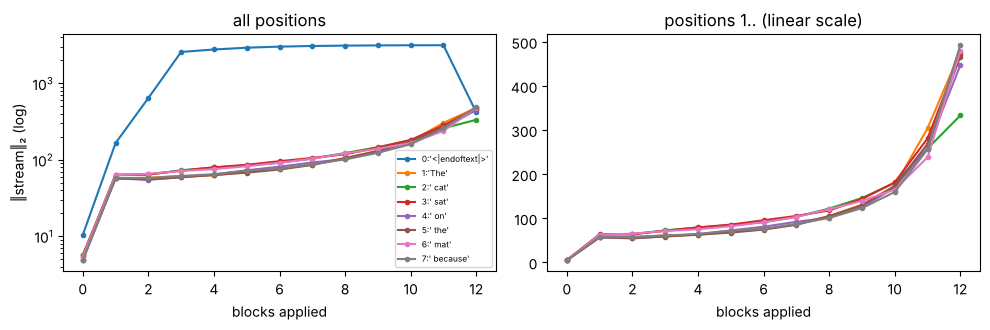

In [8]:
def stream_stack(c, n_layers):
    return torch.stack([c["blocks.0.hook_resid_pre"][0]] + [c[f"blocks.{L}.hook_resid_post"][0] for L in range(n_layers)])

S = stream_stack(cache, N_LAYERS)                 # [n_layers+1, pos, d_model]
norms = S.norm(dim=-1).numpy()
cols = [f"{i}:{t!r}" for i, t in enumerate(str_tokens)]
norm_df = pd.DataFrame(norms, columns=cols, index=pd.Index(range(N_LAYERS + 1), name="after_blocks"))
with pd.option_context("display.float_format", "{:.1f}".format):
    print(norm_df)
others = norms[:, 1:]
print("\nratio of position-0 norm to the median of positions 1.. :",
      [round(float(x), 2) for x in norms[:, 0] / np.median(others, axis=1)])
print("median norm over positions 1.. by layer :", [round(float(x), 1) for x in np.median(others, axis=1)])

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
for i in range(norms.shape[1]):
    ax[0].plot(range(N_LAYERS + 1), norms[:, i], marker="o", ms=3, color=f"C{i % 10}", label=cols[i])
ax[0].set_yscale("log"); ax[0].set_xlabel("blocks applied"); ax[0].set_ylabel("‖stream‖₂ (log)"); ax[0].set_title("all positions")
for i in range(1, norms.shape[1]):
    ax[1].plot(range(N_LAYERS + 1), norms[:, i], marker="o", ms=3, color=f"C{i % 10}")
ax[1].set_xlabel("blocks applied"); ax[1].set_title("positions 1.. (linear scale)")
ax[0].legend(fontsize=6); fig.tight_layout(); plt.show()

**What the table shows in the reference run** (GPT-2 small, this prompt, processed weights; your numbers should match
to the printed digits). The embedding (row 0) has norm about 5 at every position except position 0, the BOS token
(10.3). After one block the ordinary positions are near 57–64 and then grow steadily, to about 260 after 11 blocks and
about 470 after 12. Position 0 behaves differently: about 165 after block 1, 642 after block 2, near 2,600–3,160 from
block 3 to block 11 (30 to 43 times the median of the other positions), then 417 after block 12, below the others.
No explanation is offered here (card T10).

## 6 · Logit lens, with and without the final LayerNorm

For the stream after k blocks at the last position:

* **with norm**: `unembed(ln_final(x))`, the model's own final norm and unembedding applied early;
* **without norm**: `unembed(x)` on the *raw* weights, i.e. `W_U·x + b_U` with the norm ignored (Elhage's version).

First the check that matters: applying `ln_final` and `unembed` to the stream after the last block must reproduce the
model's logits. Describe what the table shows; it does not show that the lens is faithful (card T8).

In [9]:
def lens(m, x, use_norm):
    return m.unembed(m.ln_final(x)) if use_norm else m.unembed(x)

last = cache[f"blocks.{N_LAYERS-1}.hook_resid_post"]
print("processed: unembed(ln_final(resid_post[last])) vs model logits: max abs %.3e" % err(lens(model, last, True), logits)[0])
raw_last = raw_cache[f"blocks.{N_LAYERS-1}.hook_resid_post"]
print("raw      : unembed(ln_final(resid_post[last])) vs model logits: max abs %.3e" % err(lens(raw, raw_last, True), raw_logits)[0])
print("raw      : unembed(resid_post[last]) (no norm) vs model logits: max abs %.3e" % err(lens(raw, raw_last, False), raw_logits)[0])

final_top = logits[0, POS].argmax().item()
print("\nmodel's top next token after", repr(PROMPT), "->", repr(model.to_string([final_top])))
S_raw = stream_stack(raw_cache, N_LAYERS)
rows = []
for k in range(N_LAYERS + 1):
    with_n = lens(model, S[k:k+1], True)[0, POS]
    no_n = lens(raw, S_raw[k:k+1], False)[0, POS]
    lp = with_n.log_softmax(-1)
    rows.append(dict(after_blocks=k,
                     top1_with_norm=model.to_string([with_n.argmax().item()]),
                     logprob_final_token_with_norm=lp[final_top].item(),
                     rank_final_token_with_norm=int((with_n > with_n[final_top]).sum().item()),
                     top1_without_norm_raw=model.to_string([no_n.argmax().item()]),
                     rank_final_token_without_norm=int((no_n > no_n[final_top]).sum().item())))
lens_df = pd.DataFrame(rows).set_index("after_blocks")
with pd.option_context("display.float_format", "{:.3f}".format):
    print(lens_df)

processed: unembed(ln_final(resid_post[last])) vs model logits: max abs 0.000e+00
raw      : unembed(ln_final(resid_post[last])) vs model logits: max abs 0.000e+00
raw      : unembed(resid_post[last]) (no norm) vs model logits: max abs 8.346e+02

model's top next token after 'The cat sat on the mat because' -> ' it'


             top1_with_norm  logprob_final_token_with_norm  rank_final_token_with_norm top1_without_norm_raw  rank_final_token_without_norm
after_blocks                                                                                                                               
0                    destro                        -31.656                        2025               because                            377
1                       the                         -1.805                           1                   the                              4
2                       the                         -2.309                           2                   the                              4
3                        of                         -2.217                           3                   the                              4
4                      they                         -2.761                           4                   the                              4
5                   

## 7 · The W9 toy world in numpy (card §7, §9)

Every toy number in the card, recomputed and asserted. Two-dimensional stream, toy numbers (ours).

In [10]:
v = lambda *a: np.array(a, dtype=float)
close = lambda a, b: np.allclose(a, b, atol=5e-4)
r3 = lambda a: np.round(a, 3)

# W9-A, the sum
x0, a1, f1, a2, f2 = v(1, 2), v(2, -1), v(-1, 1), v(3, -2), v(-1, 2)
s_a1 = x0 + a1; x1 = s_a1 + f1; s_a2 = x1 + a2; x2 = s_a2 + f2
print("W9-A  x0", x0, "norm", r3(np.linalg.norm(x0)), "| after a1", s_a1, "| x1", x1, "norm", r3(np.linalg.norm(x1)),
      "| after a2", s_a2, "| x2", x2, "norm", r3(np.linalg.norm(x2)))
assert close(s_a1, (3, 1)) and close(x1, (2, 2)) and close(s_a2, (5, 0)) and close(x2, (4, 2))
assert close([np.linalg.norm(x0), np.linalg.norm(x1), np.linalg.norm(x2)], [2.236, 2.828, 4.472])
assert close(x0 + a1 + f1 + a2 + f2, (4, 2))
print("      cancellation in y: a2 writes", a2[1], ", f2 writes", f2[1], "-> net", a2[1] + f2[1])
assert a2[1] + f2[1] == 0

# Guess-first Q2: (2,2) + (-2,-2)
print("Q2    (2,2) + (-2,-2) =", v(2, 2) + v(-2, -2))

# W9-B, who hears whom
r = v(1, 2)
shares = {"x0": float(r @ x0), "a1": float(r @ a1), "f1": float(r @ f1), "a2": float(r @ a2)}
print("W9-B  r·(5,0) =", r @ s_a2, "| shares", shares, "| sum", sum(shares.values()))
assert r @ s_a2 == 5 and list(shares.values()) == [5, 0, 1, -1]

# W9-C, the cloud
calm, urgent = np.array([(3, 1), (4, 2), (5, 3)], float), np.array([(1, 3), (2, 4), (3, 5)], float)
assert close(calm[1], x2)
u_at = lambda deg: v(math.cos(math.radians(deg)), math.sin(math.radians(deg)))
def margin(deg):
    sc, su = calm @ u_at(deg), urgent @ u_at(deg)
    return max(su.min() - sc.max(), sc.min() - su.max())
for deg in [0, 90, 135, 45]:
    print(f"W9-C  phi={deg:3d}: calm {r3(calm @ u_at(deg)) + 0.0}  urgent {r3(urgent @ u_at(deg)) + 0.0}  margin {round(margin(deg), 3) + 0.0:.3f}")
assert close(calm @ u_at(0), (3, 4, 5)) and close(urgent @ u_at(0), (1, 2, 3))
assert close(calm @ u_at(90), (1, 2, 3)) and close(urgent @ u_at(90), (3, 4, 5))
assert close(calm @ u_at(135), [-1.414] * 3) and close(urgent @ u_at(135), [1.414] * 3)
assert close(calm @ u_at(45), np.array([4, 6, 8]) / math.sqrt(2)) and close(urgent @ u_at(45), np.array([4, 6, 8]) / math.sqrt(2))
table = {deg: float(round(margin(deg), 3)) + 0.0 for deg in [0, 45, 90, 100, 120, 135, 150, 170, 180]}
print("      margin by phi:", table)
assert table == {0: 0.0, 45: -2.828, 90: 0.0, 100: 0.695, 120: 2.0, 135: 2.828, 150: 2.0, 170: 0.695, 180: 0.0}

# steering
def shift(phi, psi, alpha):
    return u_at(phi) @ (alpha * u_at(psi))
for phi, psi, alpha in [(135, 135, 2), (135, 45, 2)]:
    vv = alpha * u_at(psi)
    d_calm, d_urg = (calm + vv) @ u_at(phi) - calm @ u_at(phi), (urgent + vv) @ u_at(phi) - urgent @ u_at(phi)
    print(f"steer phi={phi} psi={psi} alpha={alpha}: u·v={shift(phi, psi, alpha):.3f} = alpha*cos(phi-psi)="
          f"{alpha * math.cos(math.radians(phi - psi)):.3f}; calm -> {r3((calm + vv) @ u_at(phi))}, urgent -> {r3((urgent + vv) @ u_at(phi))}")
    assert close(d_calm, shift(phi, psi, alpha)) and close(d_urg, shift(phi, psi, alpha))
assert close((calm + 2 * u_at(135)) @ u_at(135), [0.586] * 3) and close((urgent + 2 * u_at(135)) @ u_at(135), [3.414] * 3)
assert close(shift(135, 45, 2), 0)

# Guess-first Q3: same shift for every point
vq, uq, pts = v(0.7, -1.3), u_at(30), np.vstack([calm, urgent])
print("Q3    score change of each of the six points:", r3((pts + vq) @ uq - pts @ uq), "= u·v =", r3(uq @ vq))
assert close((pts + vq) @ uq - pts @ uq, [uq @ vq] * 6)

# E1 variation: f2 = -a2 leaves block 2's net write zero
print("E1    f2 = -a2 =", -a2, "-> a2 + f2 =", a2 + (-a2))
assert close(-a2, (-3, 2))
# E4
u135 = u_at(135)
print("E4    v=(-2,2): u·v =", r3(u135 @ v(-2, 2)), "| v=(2,2): u·v =", r3(u135 @ v(2, 2)), "| seen at phi=45: u·v =", r3(u_at(45) @ v(2, 2)))
assert close(u135 @ v(-2, 2), 2.828) and close(u135 @ v(2, 2), 0) and close(u_at(45) @ v(2, 2), 2.828)
# E5, rotation by 90 degrees
R = np.array([[0, -1], [1, 0]], float)
rot_shares = [float((R @ r) @ (R @ w)) for w in (x0, a1, f1, a2)]
print("E5    read-shares after rotating everything by 90°:", rot_shares, "| coordinate 2 of the stream before/after:", x2[1], (R @ x2)[1])
assert close(rot_shares, [5, 0, 1, -1])

# Open question for post 04 (matrix-vector products only)
M = np.array([[2, 1], [1, 2]], float)
print("Open  M(1,0) =", M @ v(1, 0), "| M(1,1) =", M @ v(1, 1), "| M(1,-1) =", M @ v(1, -1))
assert close(M @ v(1, 0), (2, 1)) and close(M @ v(1, 1), (3, 3)) and close(M @ v(1, -1), (1, -1))
print("\nAll W9 / E1–E5 / open-question numbers reproduced.")

W9-A  x0 [1. 2.] norm 2.236 | after a1 [3. 1.] | x1 [2. 2.] norm 2.828 | after a2 [5. 0.] | x2 [4. 2.] norm 4.472
      cancellation in y: a2 writes -2.0 , f2 writes 2.0 -> net 0.0
Q2    (2,2) + (-2,-2) = [0. 0.]
W9-B  r·(5,0) = 5.0 | shares {'x0': 5.0, 'a1': 0.0, 'f1': 1.0, 'a2': -1.0} | sum 5.0
W9-C  phi=  0: calm [3. 4. 5.]  urgent [1. 2. 3.]  margin 0.000
W9-C  phi= 90: calm [1. 2. 3.]  urgent [3. 4. 5.]  margin 0.000
W9-C  phi=135: calm [-1.414 -1.414 -1.414]  urgent [1.414 1.414 1.414]  margin 2.828
W9-C  phi= 45: calm [2.828 4.243 5.657]  urgent [2.828 4.243 5.657]  margin -2.828
      margin by phi: {0: 0.0, 45: -2.828, 90: 0.0, 100: 0.695, 120: 2.0, 135: 2.828, 150: 2.0, 170: 0.695, 180: 0.0}
steer phi=135 psi=135 alpha=2: u·v=2.000 = alpha*cos(phi-psi)=2.000; calm -> [0.586 0.586 0.586], urgent -> [3.414 3.414 3.414]
steer phi=135 psi=45 alpha=2: u·v=-0.000 = alpha*cos(phi-psi)=0.000; calm -> [-1.414 -1.414 -1.414], urgent -> [1.414 1.414 1.414]
Q3    score change of each of 

## 8 · TransformerLens versus Hugging Face GPT-2 (card T6)

Hugging Face `GPT2LMHeadModel` is run on the **same token ids** (with the BOS token TransformerLens prepended) and with
`attn_implementation="eager"`, as the TransformerLens loader source recommends for a like-for-like comparison.
`hidden_states[k]` is compared with the stream after k blocks, from the raw and from the processed TransformerLens model.

What to look for: raw should match; processed should differ, and the cell tests one specific guess about *how* it differs,
namely that the processed stream is the Hugging Face stream minus its own mean over the 768 coordinates (what centring
every writing weight would do). The last Hugging Face entry is compared both with the stream after the last block and
with the output of the final LayerNorm.

In [11]:
from transformers import AutoModelForCausalLM
hf = AutoModelForCausalLM.from_pretrained(TL_MODEL, dtype=DTYPE, attn_implementation="eager",
                                          local_files_only=LOCAL_ONLY).eval()
out = hf(tokens, output_hidden_states=True)
hs = out.hidden_states
print("len(hidden_states) =", len(hs), "for", hf.config.num_hidden_layers, "blocks")
S_raw_full = [raw_cache["blocks.0.hook_resid_pre"]] + [raw_cache[f"blocks.{L}.hook_resid_post"] for L in range(N_LAYERS)]
S_proc_full = [cache["blocks.0.hook_resid_pre"]] + [cache[f"blocks.{L}.hook_resid_post"] for L in range(N_LAYERS)]
center = lambda t: t - t.mean(-1, keepdim=True)
rows = []
for k in range(N_LAYERS + 1):
    rows.append(dict(k=k,
                     raw_vs_hf_abs=err(S_raw_full[k], hs[k])[0], raw_vs_hf_rel=err(S_raw_full[k], hs[k])[1],
                     proc_vs_hf_rel=err(S_proc_full[k], hs[k])[1],
                     proc_vs_centered_hf_abs=err(S_proc_full[k], center(hs[k]))[0],
                     proc_vs_centered_hf_rel=err(S_proc_full[k], center(hs[k]))[1],
                     hf_mean_coord_absmax=hs[k].mean(-1).abs().max().item()))
cmp_df = pd.DataFrame(rows).set_index("k")
with pd.option_context("display.float_format", "{:.2e}".format):
    print(cmp_df)
print("\nlast entry: raw ln_final(stream after last block) vs hidden_states[-1]: max abs %.3e"
      % err(raw.ln_final(raw_cache[f"blocks.{N_LAYERS-1}.hook_resid_post"]), hs[-1])[0])
print("embedding : HF wte(ids)+wpe(pos) vs raw hook_embed+hook_pos_embed: max abs %.3e" %
      err(hf.transformer.wte(tokens) + hf.transformer.wpe(torch.arange(tokens.shape[1])[None]),
          raw_cache["hook_embed"] + raw_cache["hook_pos_embed"])[0])
print("\nlogits raw TL vs HF                    : max abs %.3e" % err(raw_logits, out.logits)[0])
print("logits processed TL vs HF              : max abs %.3e" % err(logits, out.logits)[0])
print("logits processed TL vs HF − vocab mean : max abs %.3e" % err(logits, center(out.logits))[0])
print("log-softmax processed TL vs HF         : max abs %.3e" % err(logits.log_softmax(-1), out.logits.log_softmax(-1))[0])
ratios = torch.stack([S_proc_full[k][0].norm(dim=-1) / S_raw_full[k][0].norm(dim=-1) for k in range(N_LAYERS + 1)])
print("norm ratio processed/raw stream, min and max over positions, by k:")
print("  min:", [round(float(x), 4) for x in ratios.min(dim=1).values])
print("  max:", [round(float(x), 4) for x in ratios.max(dim=1).values])

len(hidden_states) = 13 for 12 blocks
    raw_vs_hf_abs  raw_vs_hf_rel  proc_vs_hf_rel  proc_vs_centered_hf_abs  proc_vs_centered_hf_rel  hf_mean_coord_absmax
k                                                                                                                       
0        0.00e+00       0.00e+00        2.49e-02                 1.19e-07                 6.33e-08              5.76e-03
1        2.29e-05       2.77e-07        2.55e-02                 3.81e-05                 5.24e-07              8.20e-02
2        1.22e-04       3.45e-07        3.55e-02                 6.10e-05                 5.50e-07              8.22e-01
3        4.88e-04       4.43e-07        4.26e-02                 2.44e-04                 7.06e-07              3.96e+00
4        2.44e-04       7.81e-07        4.28e-02                 7.32e-04                 1.09e-06              4.29e+00
5        2.44e-04       6.44e-07        4.27e-02                 4.88e-04                 9.79e-07              4.5

The source lines behind section 8 (installed versions): how `hidden_states` is collected in transformers, and what the
TransformerLens processing does to the writing weights and the unembedding.

In [12]:
cite("transformers.utils.output_capturing", r"Historically, the first hidden_states output is actually the input of layer 0", context=2)
cite("transformers.utils.output_capturing", r"collected_outputs\[key\].append\(args\[0\]\)")
cite("transformers.utils.output_capturing", r"Whether to overwrite `out.hidden_states\[-1\]` with the `out.last_hidden_state`", context=2)
cite("transformers.utils.output_capturing", r"collected_outputs\[key\].append\(outputs.last_hidden_state\)", context=1)
cite("transformers.models.gpt2.modeling_gpt2", r'"hidden_states": GPT2Block')
cite("transformers.models.gpt2.modeling_gpt2", r"hidden_states = inputs_embeds \+ position_embeds")
cite("transformers.models.gpt2.modeling_gpt2", r"hidden_states = self.ln_f\(hidden_states\)")
cite("transformers.models.gpt2.modeling_gpt2", r"_tied_weights_keys")
print()
cite("transformer_lens.weight_processing", r"Centers the weights of the model that write to the residual stream", context=1)
cite("transformer_lens.weight_processing", r"embed_W_E = embed_W_E - embed_W_E.mean\(-1, keepdim=True\)")
cite("transformer_lens.weight_processing", r"pos_embed_W_pos = pos_embed_W_pos - pos_embed_W_pos.mean\(-1, keepdim=True\)")
cite("transformer_lens.weight_processing", r"As softmax is translation invariant, this changes the logits but not the log", context=1)
cite("transformer_lens.weight_processing", r'and getattr\(cfg, "normalization_type", "LN"\) in \["LN", "LNPre"\]', start_after=r"should_center_writing_weights = \(", context=1)

transformers/utils/output_capturing.py:113:         hidden_states_layers = collected_outputs.get("_hidden_states_layers")
transformers/utils/output_capturing.py:114: 
transformers/utils/output_capturing.py:115:         # Historically, the first hidden_states output is actually the input of layer 0 (or inputs_embeds), so the hidden_states outputs
transformers/utils/output_capturing.py:116:         # have length `num_hidden_layers + 1`. When we request a list of explicit layers to capture, do not add this into the result, so
transformers/utils/output_capturing.py:117:         # that the indexing of the output is the same as the actual requested layers
transformers/utils/output_capturing.py:124:             collected_outputs[key].append(args[0])
transformers/utils/output_capturing.py:241:     Args:
transformers/utils/output_capturing.py:242:         tie_last_hidden_states (`bool`, *optional*, defaults to `True`):
transformers/utils/output_capturing.py:243:             Whether to overwrite

## 9 · Your turn (blank exercise cells)

Use the W9 numbers in section 7 or, for the brave, the real stream `cache` above.

**E1 · Add.** With W9-A, compute x₁ and x₂, then check x₂ = x₀ + a₁ + f₁ + a₂ + f₂. What must f₂ be for block 2 to leave
the stream unchanged?

In [13]:
# E1: your code here

**E2 · Who hears whom.** Compute r·x₀, r·a₁, r·f₁, r·a₂ for r = (1, 2); show they add to r·(5, 0). Which writer is
inaudible, and why?

In [14]:
# E2: your code here

**E3 · Project.** Score the six W9-C points on (1, 0), (0, 1) and (−1, 1)/√2. Which direction leaves a gap?

In [15]:
# E3: your code here

**E4 · Steer.** Add v = (−2, 2) to every point and show each score on u = (−1, 1)/√2 rises by u·v. Then add v = (2, 2).
Which probe angle would see it?

In [16]:
# E4: your code here

**E5 · Rotate.** Rotate every vector by 90° ((x, y) → (−y, x)), including r. Show the four read-shares are unchanged.
What does that say about "coordinate 2 of the stream"?

In [17]:
# E5: your code here